# ПЗ-5. Измерение галлюцинаций (POPE)

**Цель.** Построить POPE-подобный тест на 100 изображениях COCO val2017, измерить склонность Qwen2.5-VL-3B-Instruct к галлюцинациям объектов и проверить влияние промпта.

**Оборудование.** Google Colab, GPU T4 16 ГБ, веса в fp16 (bf16 на T4 аппаратно не поддерживается). Полный прогон ≈ 40–60 минут.
Ответы модели сохраняются в `pz5_answers.csv` после каждого изображения: если среда Colab отключилась, достаточно заново выполнить ячейки — готовые ответы будут пропущены.

**Вклад.** Работа выполнена индивидуально: код, эксперименты и выводы — автор отчёта.

**Данные.** Только открытые данные: изображения и аннотации COCO 2017 (официальный сервер cocodataset.org). Персональные документы в модель не загружаются.

In [1]:
# Проверка устройства, на котором выполняется ноутбук
import sys, os, platform, shutil, subprocess
IN_COLAB = 'google.colab' in sys.modules or os.path.isdir('/content')
print('Среда:', 'Google Colab' if IN_COLAB else 'локальная машина', '|', platform.platform(), '| Python', platform.python_version())
print('CPU:', platform.processor() or platform.machine(), '| логических ядер:', os.cpu_count())
try:
    import psutil
    print(f'RAM: {psutil.virtual_memory().total / 2**30:.1f} ГБ | свободно на диске: {shutil.disk_usage(".").free / 2**30:.0f} ГБ')
except ImportError:
    print(f'Свободно на диске: {shutil.disk_usage(".").free / 2**30:.0f} ГБ')
import torch
print('torch', torch.__version__, '| CUDA', torch.version.cuda, '| GPU доступен:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('GPU не найден. В Colab: Среда выполнения → Сменить среду выполнения → GPU T4, затем перезапустите ноутбук.')
props = torch.cuda.get_device_properties(0)
print(f'GPU: {props.name} | память {props.total_memory / 2**30:.1f} ГБ | compute capability {props.major}.{props.minor} | устройств: {torch.cuda.device_count()}')
if shutil.which('nvidia-smi'):
    print(subprocess.run(['nvidia-smi'], capture_output=True, text=True).stdout)
# свободная видеопамять и чужие процессы на GPU — через nvidia-smi (не требует создания CUDA-контекста)
q = lambda *a: subprocess.run(['nvidia-smi', *a, '--format=csv,noheader,nounits'], capture_output=True, text=True).stdout.strip()
free_mb, total_mb = map(int, q('--query-gpu=memory.free,memory.total').split(','))
print(f'Свободно видеопамяти: {free_mb / 1024:.1f} из {total_mb / 1024:.1f} ГБ')
if free_mb < 10 * 1024:
    procs = [l.split(', ') for l in q('--query-compute-apps=pid,used_memory').splitlines() if l]
    pids = [p for p, _ in procs if int(p) != os.getpid()]
    print('GPU занимают процессы (pid, МБ):', procs)
    raise RuntimeError('GPU занят другими ядрами на этом Colab-сервере. Выполните в отдельной ячейке:  !kill -9 ' + ' '.join(pids) +
                       '  — затем перезапустите ядро этого ноутбука (Restart) и Run All. '
                       'Либо Ctrl+Shift+P → Colab: Remove Server и создайте новый сервер GPU T4.')
if 'T4' not in props.name:
    print('Внимание: задание рассчитано на T4 16 ГБ (fp16). На другой GPU время и расход памяти будут отличаться.')

Среда: Google Colab | Linux-6.6.159+-x86_64-with-glibc2.39 | Python 3.13.16
CPU: x86_64 | логических ядер: 2
RAM: 12.7 ГБ | свободно на диске: 113 ГБ
torch 2.14.1+cu130 | CUDA 13.0 | GPU доступен: True
GPU: Tesla T4 | память 14.6 ГБ | compute capability 7.5 | устройств: 1
Thu Nov 12 22:57:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000

In [2]:
%pip install -q transformers==4.51.3 huggingface_hub==0.30.2 accelerate==1.6.0 pycocotools

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.30.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.30.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.30.2 which is incompatible.


In [3]:
import os, re, json, time, random, zipfile, platform, importlib.metadata as md
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
from urllib.request import urlretrieve
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from PIL import Image
import transformers
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
from huggingface_hub import model_info
assert transformers.__version__ == '4.51.3', 'После %pip выполните Runtime → Restart session и запустите ячейки заново'

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
assert torch.cuda.is_available(), 'Выберите в Colab среду выполнения с GPU T4'
DEVICE = 'cuda'
print('GPU:', torch.cuda.get_device_name(), '| Python', platform.python_version())
for p in ['torch', 'transformers', 'huggingface_hub', 'accelerate', 'pycocotools', 'numpy', 'pandas', 'pillow']:
    print(f'{p:16s}', md.version(p))

MID = 'Qwen/Qwen2.5-VL-3B-Instruct'
MR = '66285546d2b821cf421d4f5eb2576359d3770cd3'   # зафиксированная ревизия весов
print('Модель:', MID, '| ревизия:', MR, '| актуальная на Hub:', model_info(MID).sha)

GPU: Tesla T4 | Python 3.13.16
torch            2.14.1+cu130
transformers     4.51.3
huggingface_hub  0.30.2
accelerate       1.6.0
pycocotools      2.0.11
numpy            2.4.6
pandas           2.2.3
pillow           11.3.0
Модель: Qwen/Qwen2.5-VL-3B-Instruct | ревизия: 66285546d2b821cf421d4f5eb2576359d3770cd3 | актуальная на Hub: 66285546d2b821cf421d4f5eb2576359d3770cd3


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


## 1. Аннотации COCO и статистика train

* **popular** — объекты, встречающиеся на наибольшем числе изображений train2017;
* **adversarial** — для каждого изображения отсутствующие объекты ранжируются по суммарной частоте совместной встречаемости с присутствующими объектами: $\text{score}(c)=\sum_{p\in\text{present}}\text{co}(c,p)$, где $\text{co}(c,p)$ — число изображений train2017, на которых есть оба класса.

Статистика считается только по train2017, вопросы строятся по val2017 — разделы не пересекаются.

In [4]:
ROOT = Path('coco'); ROOT.mkdir(exist_ok=True)
need = ['annotations/instances_train2017.json', 'annotations/instances_val2017.json']
if not all((ROOT / n).exists() for n in need):
    z = ROOT / 'annotations_trainval2017.zip'
    if not z.exists():
        print('Скачиваю аннотации COCO (~240 МБ)...')
        urlretrieve('http://images.cocodataset.org/annotations/annotations_trainval2017.zip', z)
    with zipfile.ZipFile(z) as f:
        for n in need: f.extract(n, ROOT)

with open(ROOT / 'annotations/instances_train2017.json') as f: tr = json.load(f)
cats = {c['id']: c['name'] for c in tr['categories']}
img_cats = defaultdict(set)
for a in tr['annotations']: img_cats[a['image_id']].add(a['category_id'])
del tr
freq = Counter()                          # на скольких изображениях train встречается класс
co = np.zeros((91, 91), dtype=np.int64)   # совместная встречаемость классов (id COCO ≤ 90)
for s in img_cats.values():
    freq.update(s)
    for a, b in combinations(sorted(s), 2):
        co[a, b] += 1; co[b, a] += 1
popular = [c for c, _ in freq.most_common()]
print('Изображений train с объектами:', len(img_cats), '| классов:', len(cats))
print('Топ-10 popular:', [cats[c] for c in popular[:10]])
for name in ['dining table', 'surfboard', 'keyboard']:
    cid = [k for k, v in cats.items() if v == name][0]
    print(f'Чаще всего вместе с «{name}»:', [cats[j] for j in np.argsort(-co[cid])[:5]])
del img_cats

Скачиваю аннотации COCO (~240 МБ)...
Изображений train с объектами: 117266 | классов: 80
Топ-10 popular: ['person', 'chair', 'car', 'dining table', 'cup', 'bottle', 'bowl', 'handbag', 'truck', 'bench']
Чаще всего вместе с «dining table»: ['person', 'chair', 'cup', 'bowl', 'bottle']
Чаще всего вместе с «surfboard»: ['person', 'boat', 'kite', 'car', 'dog']
Чаще всего вместе с «keyboard»: ['mouse', 'tv', 'laptop', 'chair', 'book']


## 2. Выбор 100 изображений val2017 и генерация вопросов

* Позитивы: 3 класса, присутствующие на изображении. Чтобы позитивный вопрос не касался почти невидимого объекта, берутся классы, у которых хотя бы один не-crowd экземпляр занимает ≥ 1 % площади; изображение подходит, если таких классов ≥ 3.
* Негативы: класс отсутствует среди **всех** аннотаций изображения (включая мелкие и crowd-объекты). По 3 негатива на изображение в каждом режиме.
* В каждом режиме 300 позитивов + 300 негативов, баланс 1 : 1, как в POPE. Позитивные вопросы общие для трёх режимов.

In [5]:
with open(ROOT / 'annotations/instances_val2017.json') as f: va = json.load(f)
val_imgs = {m['id']: m for m in va['images']}
val_anns = defaultdict(list)
for a in va['annotations']: val_anns[a['image_id']].append(a)
del va

MIN_AREA = 0.01
cands = []
for iid in sorted(val_imgs):
    m = val_imgs[iid]; anns = val_anns[iid]
    present = {a['category_id'] for a in anns}
    big = sorted({a['category_id'] for a in anns if not a['iscrowd'] and a['area'] >= MIN_AREA * m['width'] * m['height']})
    if len(big) >= 3: cands.append((iid, present, big))
rng = random.Random(SEED)
rng.shuffle(cands)
chosen = cands[:100]
print('Подходящих изображений val2017:', len(cands), '| выбрано:', len(chosen))

def article(w): return 'an' if w[0] in 'aeiou' else 'a'
def question(obj): return f'Is there {article(obj)} {obj} in the image?'

def make_questions(chosen, rng):
    rows, info = [], {}
    for iid, present, big in chosen:
        pos = rng.sample(big, 3)
        absent = [c for c in cats if c not in present]
        neg = {
            'random': rng.sample(absent, 3),
            'popular': [c for c in popular if c not in present][:3],
            'adversarial': sorted(absent, key=lambda c: (-int(co[c, sorted(present)].sum()), popular.index(c)))[:3],
        }
        info[iid] = {'present': sorted(cats[c] for c in present), 'positive': [cats[c] for c in pos],
                     **{m: [cats[c] for c in v] for m, v in neg.items()}}
        for mode, negs in neg.items():
            for c in pos:  rows.append({'image_id': iid, 'mode': mode, 'object': cats[c], 'label': 1})
            for c in negs: rows.append({'image_id': iid, 'mode': mode, 'object': cats[c], 'label': 0})
    q = pd.DataFrame(rows); q['question'] = q.object.map(question)
    return q, info

questions, qinfo = make_questions(chosen, rng)
questions.to_csv('pz5_questions.csv', index=False)
with open('pz5_question_info.json', 'w') as f: json.dump(qinfo, f, indent=1)

# проверки корректности
for mode, g in questions.groupby('mode'):
    assert len(g) == 600 and g.label.sum() == 300, mode
for iid, present, big in chosen:
    names = {cats[c] for c in present}
    g = questions[questions.image_id == iid]
    assert set(g[g.label == 1].object) <= names and not (set(g[g.label == 0].object) & names)
print('Проверки пройдены: в каждом режиме 300 позитивов и 300 негативов, негативы отсутствуют в аннотациях.')
display(questions.groupby(['mode', 'label']).size().unstack())
ex = chosen[0][0]; print('Пример, image_id', ex); display(pd.Series(qinfo[ex]))
print('Самые частые негативы по режимам:')
display(pd.DataFrame({m: questions[(questions['mode'] == m) & (questions.label == 0)].object.value_counts().head(8).index.tolist() for m in ['random', 'popular', 'adversarial']}))

Подходящих изображений val2017: 1219 | выбрано: 100
Проверки пройдены: в каждом режиме 300 позитивов и 300 негативов, негативы отсутствуют в аннотациях.


label,0,1
mode,,
adversarial,300,300
popular,300,300
random,300,300


Пример, image_id 378284


,0
present,"[dining table, fork, knife, person, pizza]"
positive,"[dining table, pizza, person]"
random,"[motorcycle, donut, skateboard]"
popular,"[chair, car, cup]"
adversarial,"[chair, cup, bottle]"


Самые частые негативы по режимам:


,random,popular,adversarial
0,stop sign,car,chair
1,elephant,chair,person
2,hot dog,dining table,car
3,bench,person,cup
4,fire hydrant,cup,dining table
5,cow,bottle,bottle
6,dining table,bowl,handbag
7,sheep,handbag,backpack


In [6]:
IMG_DIR = ROOT / 'val2017'; IMG_DIR.mkdir(exist_ok=True)
def fetch(iid):
    p = IMG_DIR / val_imgs[iid]['file_name']
    for attempt in range(4):
        if p.exists(): break
        try: urlretrieve('http://images.cocodataset.org/val2017/' + p.name, p)
        except Exception:
            if p.exists(): p.unlink()
            time.sleep(2 ** attempt)
    with Image.open(p) as im: return iid, im.convert('RGB')
with ThreadPoolExecutor(12) as pool: images = dict(pool.map(fetch, [c[0] for c in chosen]))
print('Загружено изображений:', len(images))

Загружено изображений: 100


## 3. Модель и функция запроса

Детерминированная генерация (`do_sample=False`). Разрешение изображения ограничено `max_pixels = 640·28·28 ≈ 0,5 Мпикс` — изображения COCO (≈ 640×480) обрабатываются почти без уменьшения. Вопросы одного изображения обрабатываются одним батчем с левым паддингом.

In [7]:
import gc; gc.collect()
processor = AutoProcessor.from_pretrained(MID, revision=MR, min_pixels=256 * 28 * 28, max_pixels=640 * 28 * 28)
processor.tokenizer.padding_side = 'left'
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(MID, revision=MR, torch_dtype=torch.float16, attn_implementation='sdpa',
                                                           device_map=DEVICE, low_cpu_mem_usage=True).eval()   # сразу на GPU, без копии в RAM
print(f'Модель на {model.device}, занято GPU {torch.cuda.memory_allocated() / 2**30:.1f} ГБ')
model.generation_config.update(do_sample=False, temperature=None, top_p=None, top_k=None)

@torch.inference_mode()
def chat(conversations, imgs, max_new_tokens):
    texts = [processor.apply_chat_template(c, tokenize=False, add_generation_prompt=True) for c in conversations]
    inputs = processor(text=texts, images=imgs, padding=True, return_tensors='pt').to(DEVICE)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return [s.strip() for s in processor.batch_decode(out[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)]

def user(text, with_image=True):
    content = ([{'type': 'image'}] if with_image else []) + [{'type': 'text', 'text': text}]
    return {'role': 'user', 'content': content}

# проверка, что fp16-инференс на T4 даёт осмысленный текст
iid0 = chosen[0][0]
test = chat([[user('Describe this image in one sentence.')]], [images[iid0]], 40)[0]
print('Тестовый ответ:', test); print('Объекты по аннотациям:', qinfo[iid0]['present'])
assert len(test) > 10 and not re.fullmatch(r'[!\s]*', test), 'Модель выдаёт вырожденный текст в fp16'

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (5 outputs left out)

model-00001-of-00002.safetensors:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

Тестовый ответ: A pizza with chicken and peppers on a wooden board.
Объекты по аннотациям: ['dining table', 'fork', 'knife', 'person', 'pizza']


## 4. Три промпта и приведение ответов к да / нет

1. **base** — `Is there a {object} in the image?`
2. **unsure_no** — тот же вопрос + `If you are not sure, answer no.`
3. **describe_first** — «сначала перечисли объекты, затем ответь»: двухходовой диалог. Первый ход — `List all the objects you can see in the image.` (описание генерируется один раз на изображение), второй ход — базовый вопрос. Так модель перед ответом видит собственный перечень объектов, а описание не пересчитывается для каждого из 12 вопросов.

Нормализация: в ответе ищется первое слово из {yes, no, not}; `yes` → «да», `no`/`not` → «нет» (как в POPE). Ответ без этих слов считается невалидным и засчитывается как «нет»; доля таких ответов выводится отдельно.

In [8]:
LIST_PROMPT = 'List all the objects you can see in the image.'
PROMPTS = ['base', 'unsure_no', 'describe_first']

def to_yes_no(ans):
    m = re.search(r'\b(yes|no|not)\b', ans.lower())
    return None if m is None else int(m.group(1) == 'yes')
for s, v in [('Yes.', 1), ('No, there is not.', 0), ('There is no cat in the image.', 0), ('Yes, there is a dog.', 1), ('Maybe', None)]:
    assert to_yes_no(s) == v, s

desc_path = Path('pz5_descriptions.json')
descriptions = json.loads(desc_path.read_text()) if desc_path.exists() else {}
todo = [c[0] for c in chosen if str(c[0]) not in descriptions]
for k in range(0, len(todo), 4):
    batch = todo[k:k + 4]
    for iid, d in zip(batch, chat([[user(LIST_PROMPT)] for _ in batch], [images[i] for i in batch], 128)):
        descriptions[str(iid)] = d
    desc_path.write_text(json.dumps(descriptions, ensure_ascii=False, indent=1))
print('Описаний:', len(descriptions)); print('Пример:', descriptions[str(iid0)])

def conversation(prompt, iid, q):
    if prompt == 'base': return [user(q)]
    if prompt == 'unsure_no': return [user(q + ' If you are not sure, answer no.')]
    return [user(LIST_PROMPT), {'role': 'assistant', 'content': [{'type': 'text', 'text': descriptions[str(iid)]}]}, user(q, with_image=False)]

Описаний: 100
Пример: Here are the objects visible in the image:

1. A pizza with various toppings, including what appears to be chicken, bell peppers, and possibly cheese.
2. A wooden serving board holding the pizza.
3. A black plate under the pizza.
4. A spatula with a wooden handle and metal blade, likely used for serving or cutting the pizza.
5. A fork placed on the table next to the pizza.
6. A person's arm and part of their torso in the background, suggesting someone is sitting at the table.
7. A striped tablecloth covering the table.
8. A white plate in the background, partially


In [9]:
ans_path = Path('pz5_answers.csv')
answers = pd.read_csv(ans_path) if ans_path.exists() else pd.DataFrame(columns=['prompt', 'image_id', 'object', 'raw'])
unique_q = questions.drop_duplicates(['image_id', 'object'])[['image_id', 'object', 'question']]
print('Уникальных вопросов на один промпт:', len(unique_q))
t0 = time.perf_counter()
for prompt in PROMPTS:
    done = set(answers[answers.prompt == prompt].image_id)
    for k, (iid, g) in enumerate(unique_q.groupby('image_id', sort=False)):
        if iid in done: continue
        raws = chat([conversation(prompt, iid, q) for q in g.question], [images[iid]] * len(g), 12)
        answers = pd.concat([answers, pd.DataFrame({'prompt': prompt, 'image_id': iid, 'object': g.object.values, 'raw': raws})], ignore_index=True)
        answers.to_csv(ans_path, index=False)
        if (k + 1) % 20 == 0: print(f'{prompt}: {k + 1}/100 изображений, {time.perf_counter() - t0:.0f} с')
answers['image_id'] = answers.image_id.astype(int)
answers['pred'] = answers.raw.fillna('').astype(str).map(to_yes_no)
print('Всего ответов:', len(answers)); display(answers.sample(8, random_state=SEED))

Уникальных вопросов на один промпт: 970
base: 20/100 изображений, 205 с
base: 40/100 изображений, 403 с
base: 60/100 изображений, 612 с
base: 80/100 изображений, 822 с
base: 100/100 изображений, 1027 с
unsure_no: 20/100 изображений, 1229 с
unsure_no: 40/100 изображений, 1426 с
unsure_no: 60/100 изображений, 1636 с
unsure_no: 80/100 изображений, 1851 с
unsure_no: 100/100 изображений, 2059 с
describe_first: 20/100 изображений, 2276 с
describe_first: 40/100 изображений, 2484 с
describe_first: 60/100 изображений, 2705 с
describe_first: 80/100 изображений, 2930 с
describe_first: 100/100 изображений, 3149 с
Всего ответов: 2910


,prompt,image_id,object,raw,pred
867,base,226408,airplane,There is no existence of an airplane in the im...,0.0
1221,unsure_no,218091,bench,no,0.0
874,base,434479,dining table,"Yes, there is a dining table in the image.",1.0
354,base,221708,dining table,"Yes, there is a dining table in the image.",1.0
599,base,517069,car,"Yes, there is a car in the image. It is",1.0
2560,describe_first,54592,cup,"No, there is no cup in the image.",0.0
309,base,267300,dining table,"No, there is no dining table visible in the im...",0.0
2386,describe_first,372260,couch,"No, there is no couch in the image.",0.0


## 5. Метрики: 3 режима × 3 промпта

«Да» — положительный класс. Precision = TP/(TP+FP), Recall = TP/(TP+FN), F1 — их гармоническое среднее, Yes-ratio — доля ответов «да» (при сбалансированном наборе идеальное значение 0,5). FP-rate = FP/(FP+TN) — доля галлюцинаций на негативных вопросах.

In [10]:
def metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    tp = int(((p == 1) & (y == 1)).sum()); fp = int(((p == 1) & (y == 0)).sum())
    fn = int(((p == 0) & (y == 1)).sum()); tn = int(((p == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0; rec = tp / (tp + fn) if tp + fn else 0.0
    return {'Accuracy': (tp + tn) / len(y), 'Precision': prec, 'Recall': rec,
            'F1': 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
            'Yes-ratio': p.mean(), 'FP-rate': fp / (fp + tn) if fp + tn else 0.0}
m = metrics([1, 1, 0, 0], [1, 0, 1, 0]); assert m['Accuracy'] == .5 and m['Precision'] == .5 and m['Recall'] == .5 and m['Yes-ratio'] == .5

full = questions.merge(answers, on=['image_id', 'object'])
assert len(full) == 3 * len(questions)
full['invalid'] = full.pred.isna(); full['pred'] = full.pred.fillna(0).astype(int)
rows = []
for (prompt, mode), g in full.groupby(['prompt', 'mode']):
    rows.append({'Промпт': prompt, 'Режим': mode, **metrics(g.label, g.pred), 'Невалидных': int(g.invalid.sum())})
table = pd.DataFrame(rows)
table['Промпт'] = pd.Categorical(table['Промпт'], PROMPTS); table['Режим'] = pd.Categorical(table['Режим'], ['random', 'popular', 'adversarial'])
table = table.sort_values(['Промпт', 'Режим']).reset_index(drop=True)
table.to_csv('pz5_metrics.csv', index=False)
display(table.style.format({c: '{:.3f}' for c in ['Accuracy', 'Precision', 'Recall', 'F1', 'Yes-ratio', 'FP-rate']}))
for col in ['F1', 'Yes-ratio', 'FP-rate']:
    print(col); display(table.pivot(index='Промпт', columns='Режим', values=col).round(3))

,Промпт,Режим,Accuracy,Precision,Recall,F1,Yes-ratio,FP-rate,Невалидных
0,base,random,0.952,0.925,0.983,0.953,0.532,0.080,2
1,base,popular,0.903,0.848,0.983,0.910,0.580,0.177,0
2,base,adversarial,0.832,0.754,0.983,0.854,0.652,0.320,0
3,unsure_no,random,0.923,0.977,0.867,0.919,0.443,0.020,0
4,unsure_no,popular,0.918,0.967,0.867,0.914,0.448,0.030,0
5,unsure_no,adversarial,0.898,0.925,0.867,0.895,0.468,0.070,0
6,describe_first,random,0.928,0.951,0.903,0.926,0.475,0.047,0
7,describe_first,popular,0.910,0.916,0.903,0.909,0.493,0.083,0
8,describe_first,adversarial,0.878,0.860,0.903,0.881,0.525,0.147,0


F1


Режим,random,popular,adversarial
Промпт,,,
base,0.953,0.910,0.854
unsure_no,0.919,0.914,0.895
describe_first,0.926,0.909,0.881


Yes-ratio


Режим,random,popular,adversarial
Промпт,,,
base,0.532,0.580,0.652
unsure_no,0.443,0.448,0.468
describe_first,0.475,0.493,0.525


FP-rate


Режим,random,popular,adversarial
Промпт,,,
base,0.080,0.177,0.320
unsure_no,0.020,0.030,0.070
describe_first,0.047,0.083,0.147


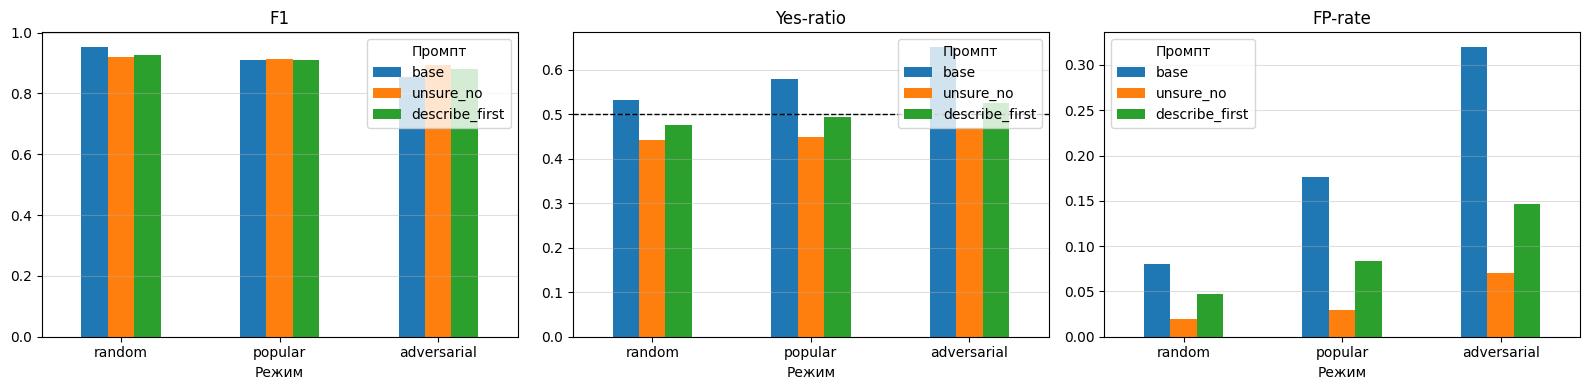

Негативные объекты, на которые модель чаще всего отвечала «да» (base):


mode         object      
adversarial  chair           22
             handbag         12
             dining table    11
             bottle           9
             backpack         8
popular      chair           23
             dining table     8
             bottle           5
             car              5
             cup              5
random       bench            5
             backpack         2
             bowl             2
             dining table     2
             handbag          2
Name: FP, dtype: int64

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['F1', 'Yes-ratio', 'FP-rate']):
    pv = table.pivot(index='Режим', columns='Промпт', values=col)
    pv.plot.bar(ax=ax, rot=0); ax.set_title(col); ax.grid(axis='y', alpha=.4)
    if col == 'Yes-ratio': ax.axhline(.5, color='k', ls='--', lw=1)
plt.tight_layout(); plt.show()

print('Негативные объекты, на которые модель чаще всего отвечала «да» (base):')
fp = full[(full.prompt == 'base') & (full.label == 0) & (full.pred == 1)]
display(fp.groupby('mode').object.value_counts().groupby(level=0).head(5).rename('FP'))

## 6. Примеры

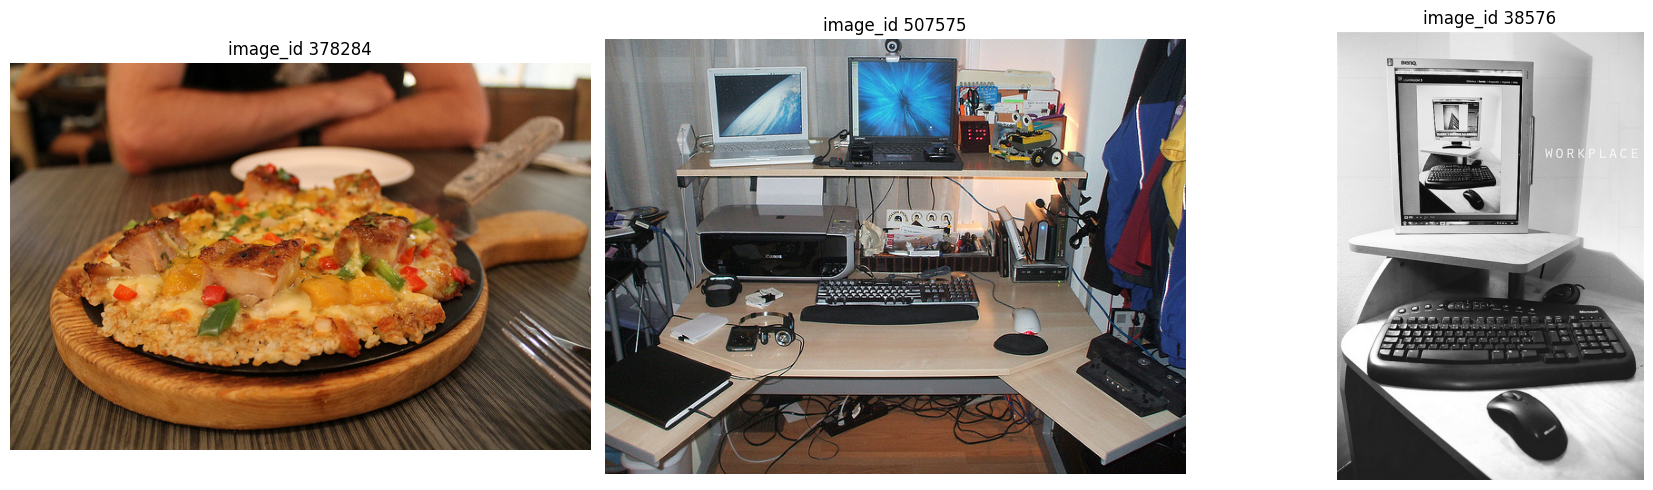

=== image_id 378284 | описание модели: Here are the objects visible in the image:

1. A pizza with various toppings, including what appears to be chicken, bell peppers, and possibly cheese.
2. A wooden serving board holding the pizza.
3. A black plate under the pizza.
4. A spatula with a wooden handle and metal blade, likely used for ser


,prompt,base,unsure_no,describe_first
object,label,,,
bottle,0,There is no existence of a bottle in the image...,no,"No, there is no bottle in the image."
car,0,There is no existence of a car in the image de...,no,"No, there is no car in the image. The image"
chair,0,"Yes, there is a chair visible in the image. It",no,"Yes, there is a chair in the image. It is"
cup,0,There is no existence of a cup in the image de...,no,"No, there is no cup in the image."
dining table,1,"Yes, there is a dining table in the image.","Yes, there is a dining table in the image.","Yes, there is a dining table in the image."
donut,0,There is no existence of a donut in the image ...,no,"No, there is no donut in the image. The"
motorcycle,0,There is no existence of a motorcycle in the i...,no,"No, there is no motorcycle in the image. The i..."
person,1,"Yes, there is a person in the image. They are","Yes, there is a person in the image. The person","Yes, there is a person in the image."
pizza,1,"Yes, there is a pizza in the image. It appears","Yes, there is a pizza in the image. It appears","Yes, there is a pizza in the image. It is"


=== image_id 507575 | описание модели: Here is a list of objects visible in the image:

1. Two computer monitors (one with a blue background and one with an Earth view)
2. A laptop on a stand
3. A keyboard
4. A mouse
5. A mousepad
6. A notebook
7. A webcam
8. A printer
9. Various cables and wires
10. A desk
11. A wall socket
12. A clothe


,prompt,base,unsure_no,describe_first
object,label,,,
book,1,"Yes, there is a book in the image. It is",yes,"Yes, there is a book in the image. It is"
car,0,There is no car present in the image.,no,"Yes, there is a toy car in the image."
chair,0,There is no chair visible in the image.,no,"No, there is no chair visible in the image."
cup,0,There is no existence of a cup in the image de...,no,"No, there is no cup in the image."
frisbee,0,There is no frisbee present in the image.,no,"No, there is no frisbee in the image."
keyboard,1,"Yes, there is a keyboard in the image. It is","Yes, there is a keyboard in the image. It is","Yes, there is a keyboard in the image. It is"
microwave,0,"No, there is no microwave in the image.",no,"No, there is no microwave in the image."
person,0,There is no person in the image.,"No, there is no person in the image.","No, there is no person in the image."
skateboard,0,"No, there is no skateboard in the image. The i...",no,"No, there is no skateboard in the image."


=== image_id 38576 | описание модели: Here is a list of the objects visible in the image:

1. Computer monitor
2. Keyboard
3. Mouse
4. Desk
5. Wall (background)


,prompt,base,unsure_no,describe_first
object,label,,,
backpack,0,There is no existence of a backpack in the ima...,no,"No, there is no backpack in the image."
car,0,There is no existence of a car in the image de...,no,"No, there is no car in the image. The image"
chair,0,There is no chair visible in the image.,no,"No, there is no chair in the image."
horse,0,There is no existence of a horse in the image ...,no,"No, there is no horse in the image. The image"
keyboard,1,"Yes, there is a keyboard in the image. It is","Yes, there is a keyboard in the image. It is","Yes, there is a keyboard in the image. It is"
laptop,0,"No, there is no laptop visible in the image. The",no,"No, there is no laptop in the image. The image"
mouse,1,"Yes, there is a mouse in the image. It is","Yes, there is a mouse in the image. It is","Yes, there is a mouse in the image. It is"
person,0,There is no person in the image.,no,"No, there is no person in the image. It only"
sports ball,0,There is no existence of a sports ball in the ...,no,"No, there is no sports ball in the image. The"


In [12]:
show = [chosen[i][0] for i in range(3)]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, iid in zip(axes, show):
    ax.imshow(images[iid]); ax.axis('off'); ax.set_title(f'image_id {iid}')
plt.tight_layout(); plt.show()
for iid in show:
    print(f'=== image_id {iid} | описание модели: {descriptions[str(iid)][:300]}')
    g = full[full.image_id == iid].drop_duplicates(['object', 'prompt']).pivot(index=['object', 'label'], columns='prompt', values='raw')
    display(g[PROMPTS])

## 7. Выводы

Ячейка ниже формирует сводку по фактическим числам прогона (все значения воспроизводятся запуском ноутбука).

In [13]:
T = table.set_index(['Промпт', 'Режим'])
b = T.loc['base']
print('Базовый промпт: F1 random / popular / adversarial = ' + ' / '.join(f"{b.loc[m, 'F1']:.3f}" for m in ['random', 'popular', 'adversarial']))
print('                FP-rate                            = ' + ' / '.join(f"{b.loc[m, 'FP-rate']:.3f}" for m in ['random', 'popular', 'adversarial']))
print('                Yes-ratio                          = ' + ' / '.join(f"{b.loc[m, 'Yes-ratio']:.3f}" for m in ['random', 'popular', 'adversarial']))
order_ok = b.loc['random', 'FP-rate'] <= b.loc['popular', 'FP-rate'] <= b.loc['adversarial', 'FP-rate']
print('Гипотеза языкового приора (FP-rate: random ≤ popular ≤ adversarial):', 'подтверждается' if order_ok else 'в строгом виде не подтверждается — см. обсуждение')
for p in PROMPTS[1:]:
    d = T.loc[p]
    print(f'{p:15s}: ΔF1(adv) = {d.loc["adversarial", "F1"] - b.loc["adversarial", "F1"]:+.3f}, '
          f'ΔRecall(adv) = {d.loc["adversarial", "Recall"] - b.loc["adversarial", "Recall"]:+.3f}, '
          f'ΔFP-rate(adv) = {d.loc["adversarial", "FP-rate"] - b.loc["adversarial", "FP-rate"]:+.3f}, '
          f'средний Yes-ratio = {d["Yes-ratio"].mean():.3f} (base {b["Yes-ratio"].mean():.3f})')
best = table.loc[table.F1.idxmax()]
print(f"Лучший F1 = {best.F1:.3f}: промпт {best['Промпт']}, режим {best['Режим']}")

Базовый промпт: F1 random / popular / adversarial = 0.953 / 0.910 / 0.854
                FP-rate                            = 0.080 / 0.177 / 0.320
                Yes-ratio                          = 0.532 / 0.580 / 0.652
Гипотеза языкового приора (FP-rate: random ≤ popular ≤ adversarial): подтверждается
unsure_no      : ΔF1(adv) = +0.041, ΔRecall(adv) = -0.117, ΔFP-rate(adv) = -0.250, средний Yes-ratio = 0.453 (base 0.588)
describe_first : ΔF1(adv) = +0.027, ΔRecall(adv) = -0.080, ΔFP-rate(adv) = -0.173, средний Yes-ratio = 0.498 (base 0.588)
Лучший F1 = 0.953: промпт base, режим random


**Как читать результат.** Recall у всех промптов вычисляется на одних и тех же 300 позитивах, поэтому различия между режимами внутри одного промпта определяются только негативами: рост FP-rate от random к popular и adversarial означает, что модель тем чаще «видит» отсутствующий объект, чем более он типичен для датасета (popular) или для данной сцены (adversarial). Это и есть проявление языкового приора: ответ определяется вероятностью «объект X обычно бывает рядом с Y», а не визуальным свидетельством. Если FP-rate во всех режимах близок к нулю, модель в этом тесте консервативна, и основное различие видно в Recall и Yes-ratio.

Инструкция «If you are not sure, answer no» сдвигает порог в сторону «нет»: Yes-ratio и FP-rate должны снижаться, но вместе с ними может падать Recall (модель начинает отказываться от реально присутствующих мелких объектов). Предварительное перечисление объектов привязывает ответ к собственному описанию модели: объект, не попавший в перечень, чаще получает «нет», а объект, ошибочно попавший в описание, закрепляет галлюцинацию. Итоговые знаки изменений приведены в сводке выше.

Ограничения: 100 изображений и 600 вопросов на режим дают стандартную ошибку accuracy около ±0,02; аннотации COCO неполны, поэтому часть «ложных» ответов «да» на negative-вопросы может быть верной (объект есть на изображении, но не размечен) — чаще всего это касается adversarial-режима.

### Контрольные вопросы

**Почему adversarial-режим труднее остальных?** Негативы в нём — объекты, которые статистически чаще всего сопровождают присутствующие (вилка рядом с обеденным столом, клавиатура рядом с монитором). Языковая модель и визуальный энкодер, обученные на таких совместных распределениях, получают сильный контекстный сигнал «объект должен быть здесь», и для правильного ответа «нет» нужно опираться только на визуальное отсутствие объекта. В random-режиме отсутствующий объект обычно не связан со сценой, и даже по контексту ясно, что его нет.

**Почему доля ответов «да» информативна сама по себе?** Набор сбалансирован 1 : 1, поэтому несмещённая модель должна отвечать «да» примерно в 50 % случаев. Yes-ratio заметно выше 0,5 указывает на склонность соглашаться (смещение в сторону галлюцинаций), ниже 0,5 — на излишнюю осторожность. Accuracy и F1 могут совпадать у моделей с противоположными смещениями, а Yes-ratio сразу показывает направление ошибки и то, какой ценой промпт улучшает FP-rate.